<a href="https://colab.research.google.com/github/NagasaiSree/ML_LabActivity/blob/main/KMeansClustering_OldFaithfulGeyser.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(272, 3)
   duration  waiting   kind
0     3.600       79   long
1     1.800       54  short
2     3.333       74   long
3     2.283       62  short
4     4.533       85   long
duration    0
waiting     0
kind        0
dtype: int64


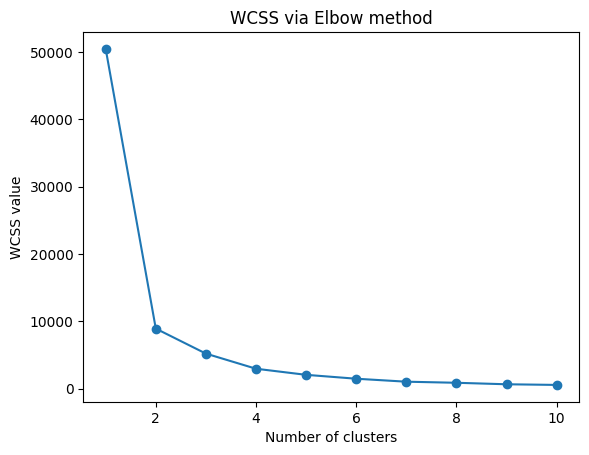

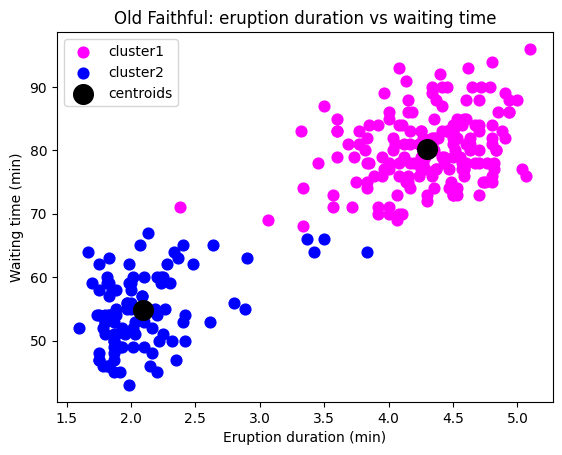

Cluster centres (duration, waiting):
 [[ 4.29793023 80.28488372]
 [ 2.09433    54.75      ]]


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/geyser.csv'
data = pd.read_csv(url)
print(data.shape)
print(data.head())
print(data.isnull().sum())

x = data[['duration', 'waiting']].values

# Elbow method to choose K
wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=21).fit(x)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker='o')
plt.title('WCSS via Elbow method'); plt.xlabel('Number of clusters'); plt.ylabel('WCSS value')
plt.show()

# Final model (K = 2: short and long eruptions)
model = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
y_means = model.fit_predict(x)

colors = ['magenta', 'blue']
for c in range(2):
    plt.scatter(x[y_means == c, 0], x[y_means == c, 1], s=60, c=colors[c], label=f'cluster{c+1}')
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], s=200, c='black', label='centroids')
plt.title('Old Faithful: eruption duration vs waiting time')
plt.xlabel('Eruption duration (min)'); plt.ylabel('Waiting time (min)')
plt.legend(); plt.show()

print('Cluster centres (duration, waiting):\n', model.cluster_centers_)